# Social Network Ads — EDA and Machine Learning
**Dataset:** `Social_Network_Ads_5000_rows.csv`  
**Target:** `Purchased` (0 = No, 1 = Yes)

This notebook adapts the complete workflow and model coverage of the supplied `best_model_training(4).ipynb` to the 5,000-row Social Network Ads dataset. Keep the CSV in the same folder as this notebook.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load dataset

In [2]:
df = pd.read_csv("Social_Network_Ads_5000_rows.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Social_Network_Ads_5000_rows.csv'

## 3. Basic inspection

In [ ]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,26990395,Male,34,28100,0
1,19111520,Female,37,56200,0
2,18936681,Male,37,149700,1
3,55486443,Female,24,28000,0
4,53030725,Female,33,31300,0


In [ ]:
df.tail()

,User ID,Gender,Age,EstimatedSalary,Purchased
4995,85477909,Female,29,64400,0
4996,95524017,Male,46,87700,0
4997,51830391,Female,40,78400,0
4998,75785196,Female,59,69300,1
4999,90308537,Male,37,15600,0


In [ ]:
df.sample(5, random_state=42)

,User ID,Gender,Age,EstimatedSalary,Purchased
1501,63418004,Female,18,19200,0
2586,51391707,Female,43,32800,0
2653,96085842,Male,18,71200,0
1055,69716374,Male,38,34000,0
705,45161364,Male,36,52100,0


In [ ]:
df.dtypes

User ID             int64
Gender             object
Age                 int64
EstimatedSalary     int64
Purchased           int64
dtype: object

In [ ]:
df.columns.to_list()

['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']

In [ ]:
df.describe(include='all')

,User ID,Gender,Age,EstimatedSalary,Purchased
count,5.000000e+03,5000,5000.000000,5000.000000,5000.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,2542,NaN,NaN,NaN
mean,5.852670e+07,NaN,37.688200,68762.000000,0.355600
std,2.425018e+07,NaN,10.571799,34325.954353,0.478743
min,1.600360e+07,NaN,18.000000,15000.000000,0.000000
25%,3.768753e+07,NaN,29.000000,41900.000000,0.000000
50%,5.869218e+07,NaN,37.000000,66400.000000,0.000000
75%,7.991629e+07,NaN,46.000000,86725.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          5000 non-null   int64 
 1   Gender           5000 non-null   object
 2   Age              5000 non-null   int64 
 3   EstimatedSalary  5000 non-null   int64 
 4   Purchased        5000 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 195.4+ KB


In [ ]:
df.shape

(5000, 5)

In [ ]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [ ]:
df.duplicated().sum()

0

## 4. Data cleaning

In [ ]:
df = df.drop_duplicates().copy()
# User ID is an identifier, not a useful predictive feature.
df = df.drop(columns=["User ID"], errors="ignore")
print(df["Purchased"].value_counts(dropna=False))
df["Purchased"] = df["Purchased"].astype(int)
df.head()

Purchased
0    3222
1    1778
Name: count, dtype: int64


,Gender,Age,EstimatedSalary,Purchased
0,Male,34,28100,0
1,Female,37,56200,0
2,Male,37,149700,1
3,Female,24,28000,0
4,Female,33,31300,0


## 5. Exploratory Data Analysis (EDA)

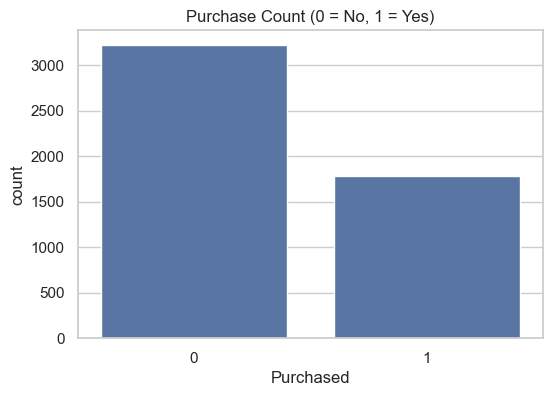

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Purchased")
plt.title("Purchase Count (0 = No, 1 = Yes)")
plt.show()

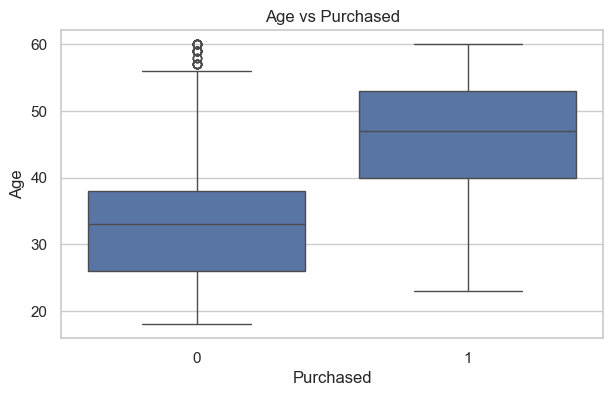

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Purchased", y="Age")
plt.title("Age vs Purchased")
plt.show()

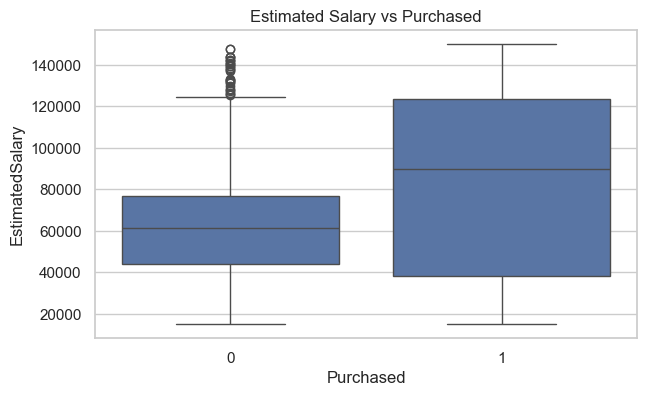

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Purchased", y="EstimatedSalary")
plt.title("Estimated Salary vs Purchased")
plt.show()

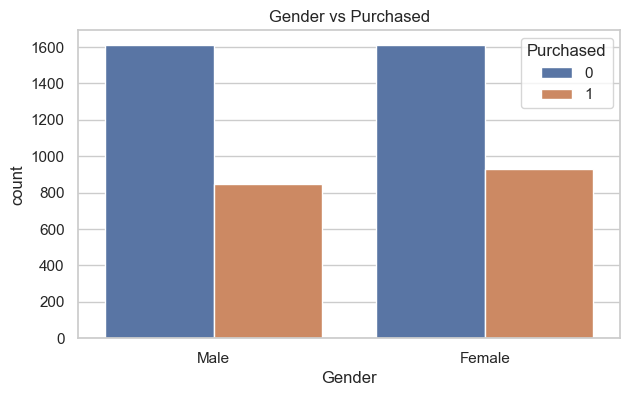

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Gender", hue="Purchased")
plt.title("Gender vs Purchased")
plt.show()

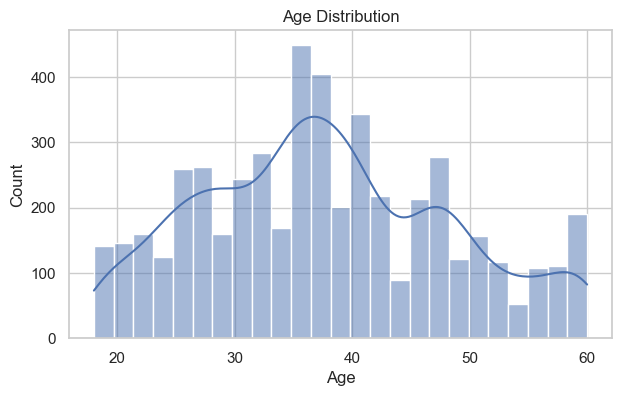

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", bins=25, kde=True)
plt.title("Age Distribution")
plt.show()

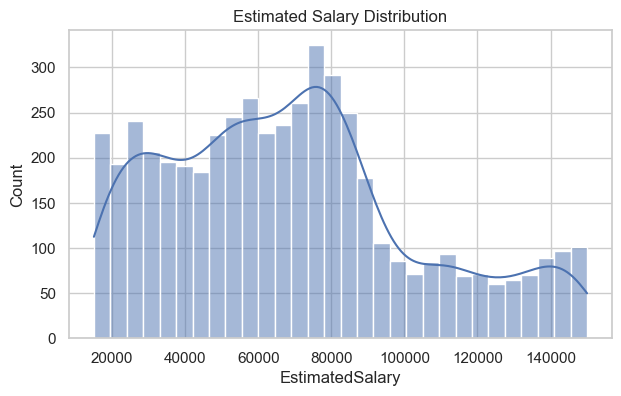

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="EstimatedSalary", bins=30, kde=True)
plt.title("Estimated Salary Distribution")
plt.show()

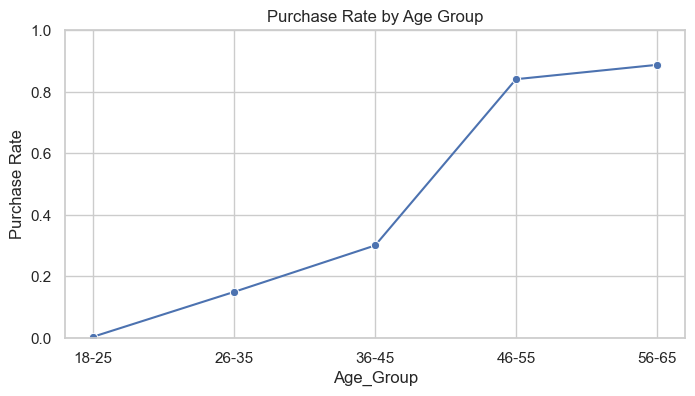

In [ ]:
df["Age_Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 65],
                          labels=["18-25", "26-35", "36-45", "46-55", "56-65"])
age_rate = df.groupby("Age_Group", observed=False)["Purchased"].mean().reset_index()
plt.figure(figsize=(8, 4))
sns.lineplot(data=age_rate, x="Age_Group", y="Purchased", marker="o")
plt.title("Purchase Rate by Age Group")
plt.ylabel("Purchase Rate")
plt.ylim(0, 1)
plt.show()

                      Age  EstimatedSalary  Purchased
Age              1.000000         0.131889   0.615253
EstimatedSalary  0.131889         1.000000   0.343288
Purchased        0.615253         0.343288   1.000000


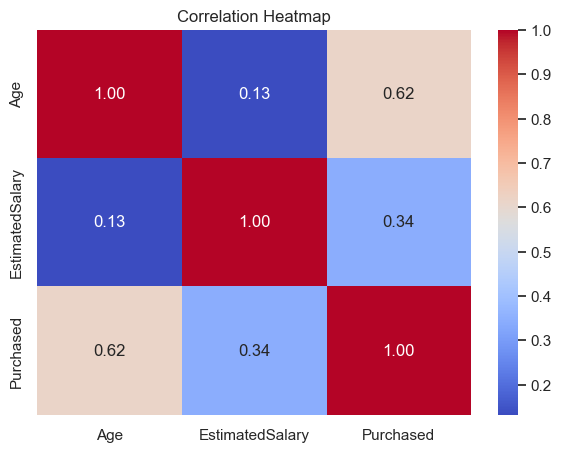

In [ ]:
corr = df.select_dtypes(include=np.number).corr()
print(corr)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 6. Prepare features and target
`Purchased` is the target. `User ID` is excluded because it is only an identifier. Convert the categorical `Gender` feature to numeric using one-hot encoding.

In [ ]:
model_df = df.drop(columns=["Age_Group"], errors="ignore").copy()
X = model_df.drop(columns=["Purchased"])
y = model_df["Purchased"]
X = pd.get_dummies(X, columns=["Gender"], drop_first=True, dtype=int)
print("Features:", X.columns.to_list())
print(y.value_counts())
X.head()

Features: ['Age', 'EstimatedSalary', 'Gender_Male']
Purchased
0    3222
1    1778
Name: count, dtype: int64


,Age,EstimatedSalary,Gender_Male
0,34,28100,1
1,37,56200,0
2,37,149700,1
3,24,28000,0
4,33,31300,0


## 7. Train-test split

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4000, 3)
X_test: (1000, 3)
y_train: (4000,)
y_test: (1000,)


## 8. Feature scaling
Fit the scaler only on training data to avoid data leakage. Scaling is used for Logistic Regression, KNN, SVC, and Gaussian Naive Bayes here.

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 9. Evaluation helper

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
model_results = []

def evaluate_model(name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    print(f"{name} Accuracy: {accuracy:.4f}")
    print("\\nConfusion Matrix:")
    print(cm)
    print("\\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))
    ConfusionMatrixDisplay(cm, display_labels=["Not Purchased", "Purchased"]).plot(
        cmap="Blues", values_format="d"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.show()
    model_results.append({"Model": name, "Accuracy": accuracy})
    return accuracy

## 10. Logistic Regression

Logistic Regression Accuracy: 0.8310
\nConfusion Matrix:
[[586  58]
 [111 245]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87       644
           1       0.81      0.69      0.74       356

    accuracy                           0.83      1000
   macro avg       0.82      0.80      0.81      1000
weighted avg       0.83      0.83      0.83      1000



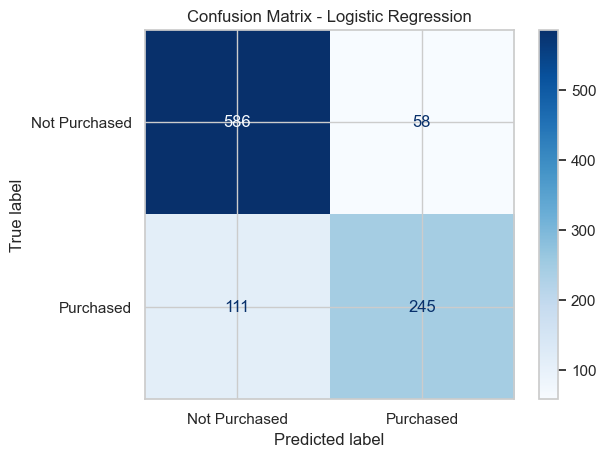

In [ ]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_scaled, y_train)
logistic_pred = logistic_model.predict(X_test_scaled)
accuracy_logistic = evaluate_model("Logistic Regression", y_test, logistic_pred)

## 11. K-Nearest Neighbors (KNN)

KNN Accuracy: 0.9220
\nConfusion Matrix:
[[603  41]
 [ 37 319]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       644
           1       0.89      0.90      0.89       356

    accuracy                           0.92      1000
   macro avg       0.91      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000



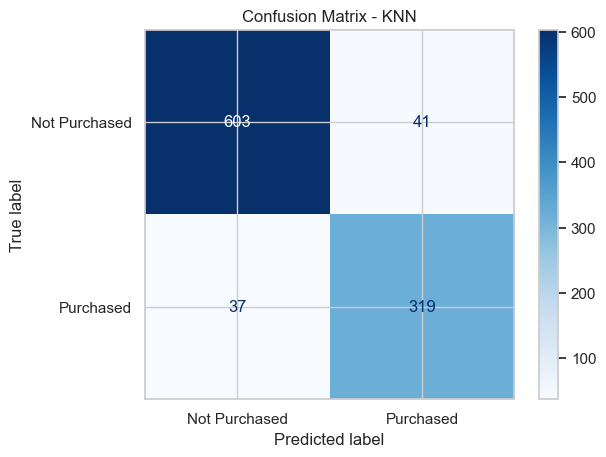

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)
accuracy_knn = evaluate_model("KNN", y_test, knn_pred)

## 12. Support Vector Classifier (SVC)

SVC Accuracy: 0.9100
\nConfusion Matrix:
[[585  59]
 [ 31 325]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.95      0.91      0.93       644
           1       0.85      0.91      0.88       356

    accuracy                           0.91      1000
   macro avg       0.90      0.91      0.90      1000
weighted avg       0.91      0.91      0.91      1000



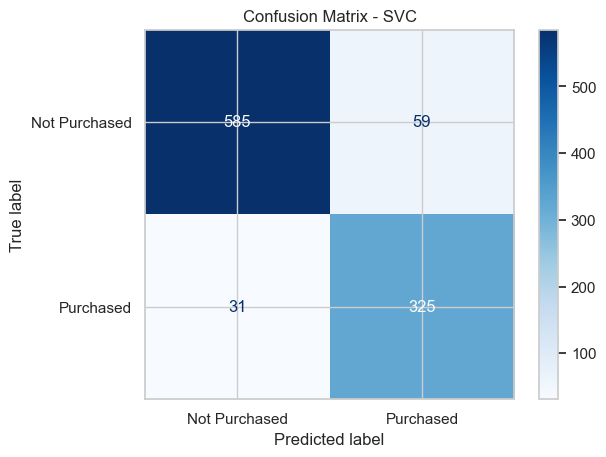

In [ ]:
from sklearn.svm import SVC
svm_model = SVC(kernel="rbf")
svm_model.fit(X_train_scaled, y_train)
svm_pred = svm_model.predict(X_test_scaled)
accuracy_svm = evaluate_model("SVC", y_test, svm_pred)

## 13. Naive Bayes

Naive Bayes Accuracy: 0.8840
\nConfusion Matrix:
[[593  51]
 [ 65 291]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91       644
           1       0.85      0.82      0.83       356

    accuracy                           0.88      1000
   macro avg       0.88      0.87      0.87      1000
weighted avg       0.88      0.88      0.88      1000



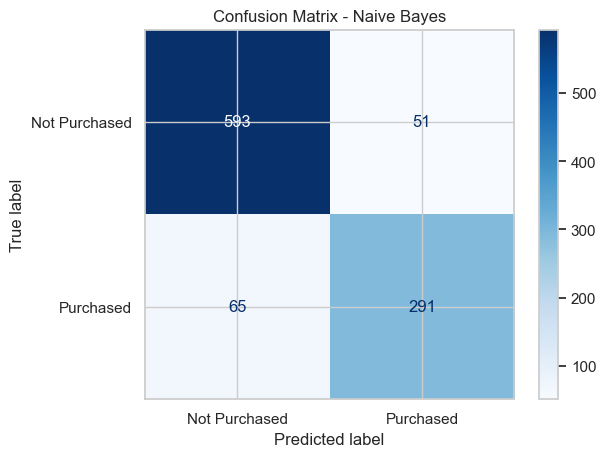

In [ ]:
from sklearn.naive_bayes import GaussianNB
naive_bayes_model = GaussianNB()
naive_bayes_model.fit(X_train_scaled, y_train)
naive_bayes_pred = naive_bayes_model.predict(X_test_scaled)
accuracy_naive_bayes = evaluate_model("Naive Bayes", y_test, naive_bayes_pred)

## 14. Decision Tree

Decision Tree Accuracy: 0.8980
\nConfusion Matrix:
[[587  57]
 [ 45 311]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       644
           1       0.85      0.87      0.86       356

    accuracy                           0.90      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.90      0.90      0.90      1000



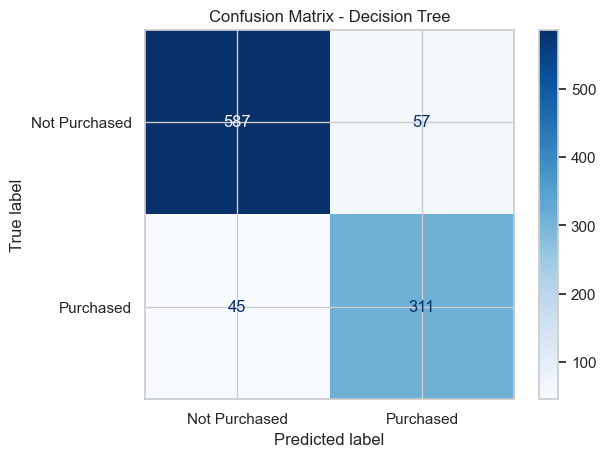

In [ ]:
from sklearn.tree import DecisionTreeClassifier
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)
decision_tree_pred = decision_tree_model.predict(X_test)
accuracy_decision_tree = evaluate_model("Decision Tree", y_test, decision_tree_pred)

## 15. Random Forest

Random Forest Accuracy: 0.9030
\nConfusion Matrix:
[[592  52]
 [ 45 311]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92       644
           1       0.86      0.87      0.87       356

    accuracy                           0.90      1000
   macro avg       0.89      0.90      0.89      1000
weighted avg       0.90      0.90      0.90      1000



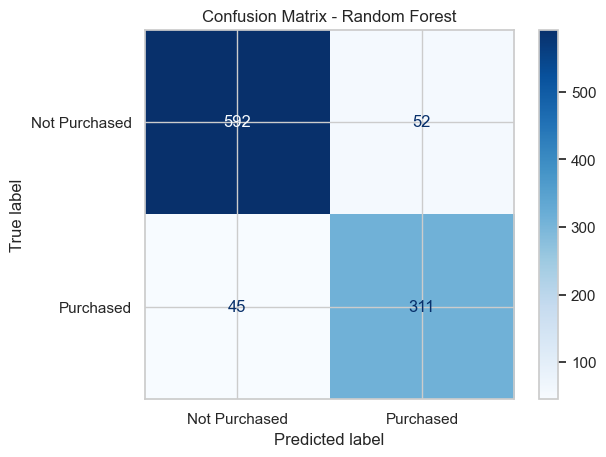

In [ ]:
from sklearn.ensemble import RandomForestClassifier
random_forest_model = RandomForestClassifier(n_estimators=100, criterion="gini", random_state=42)
random_forest_model.fit(X_train, y_train)
random_forest_pred = random_forest_model.predict(X_test)
accuracy_random_forest = evaluate_model("Random Forest", y_test, random_forest_pred)

## 16. AdaBoost

AdaBoost Accuracy: 0.8870
\nConfusion Matrix:
[[596  48]
 [ 65 291]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.91       644
           1       0.86      0.82      0.84       356

    accuracy                           0.89      1000
   macro avg       0.88      0.87      0.88      1000
weighted avg       0.89      0.89      0.89      1000



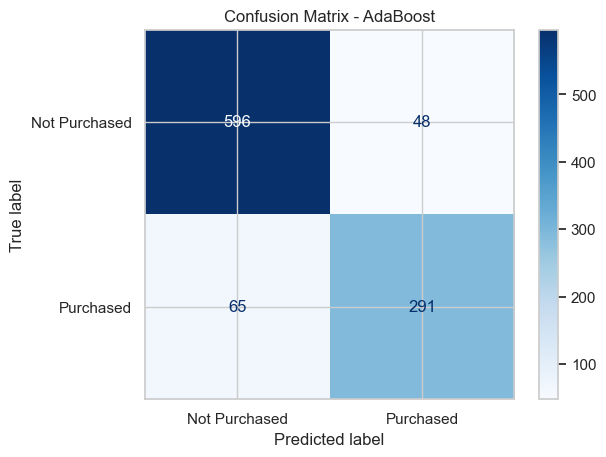

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
adaboost_model = AdaBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
adaboost_model.fit(X_train, y_train)
adaboost_pred = adaboost_model.predict(X_test)
accuracy_adaboost = evaluate_model("AdaBoost", y_test, adaboost_pred)

## 17. Gradient Boosting

Gradient Boosting Accuracy: 0.9120
\nConfusion Matrix:
[[593  51]
 [ 37 319]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       644
           1       0.86      0.90      0.88       356

    accuracy                           0.91      1000
   macro avg       0.90      0.91      0.90      1000
weighted avg       0.91      0.91      0.91      1000



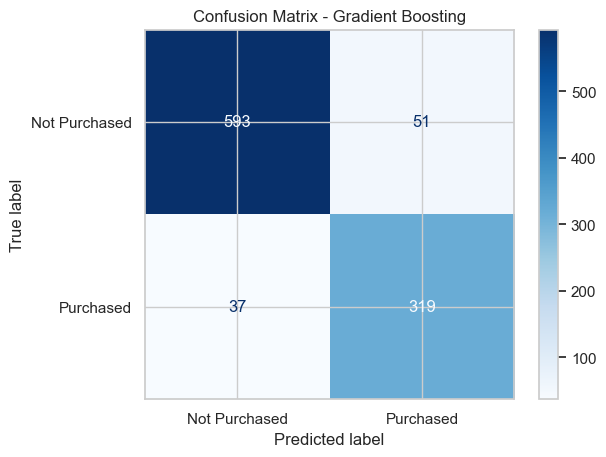

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
gradient_boost_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
)
gradient_boost_model.fit(X_train, y_train)
gradient_boost_pred = gradient_boost_model.predict(X_test)
accuracy_gradient_boost = evaluate_model("Gradient Boosting", y_test, gradient_boost_pred)

## 18. XGBoost (optional)

XGBoost Accuracy: 0.9120
\nConfusion Matrix:
[[588  56]
 [ 32 324]]
\nClassification Report:
              precision    recall  f1-score   support

           0       0.95      0.91      0.93       644
           1       0.85      0.91      0.88       356

    accuracy                           0.91      1000
   macro avg       0.90      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000



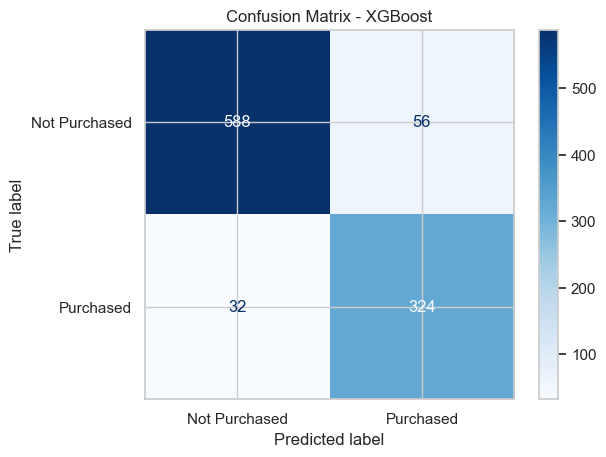

In [ ]:
try:
    from xgboost import XGBClassifier
    xgboost_model = XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3,
        eval_metric="logloss", random_state=42
    )
    xgboost_model.fit(X_train, y_train)
    xgboost_pred = xgboost_model.predict(X_test)
    accuracy_xgboost = evaluate_model("XGBoost", y_test, xgboost_pred)
except ImportError:
    print("XGBoost is not installed. Install it with: pip install xgboost")

## 19. Compare model accuracy

,Model,Accuracy
0,KNN,0.922
1,Gradient Boosting,0.912
2,XGBoost,0.912
3,SVC,0.910
4,Random Forest,0.903
5,Decision Tree,0.898
6,AdaBoost,0.887
7,Naive Bayes,0.884
8,Logistic Regression,0.831


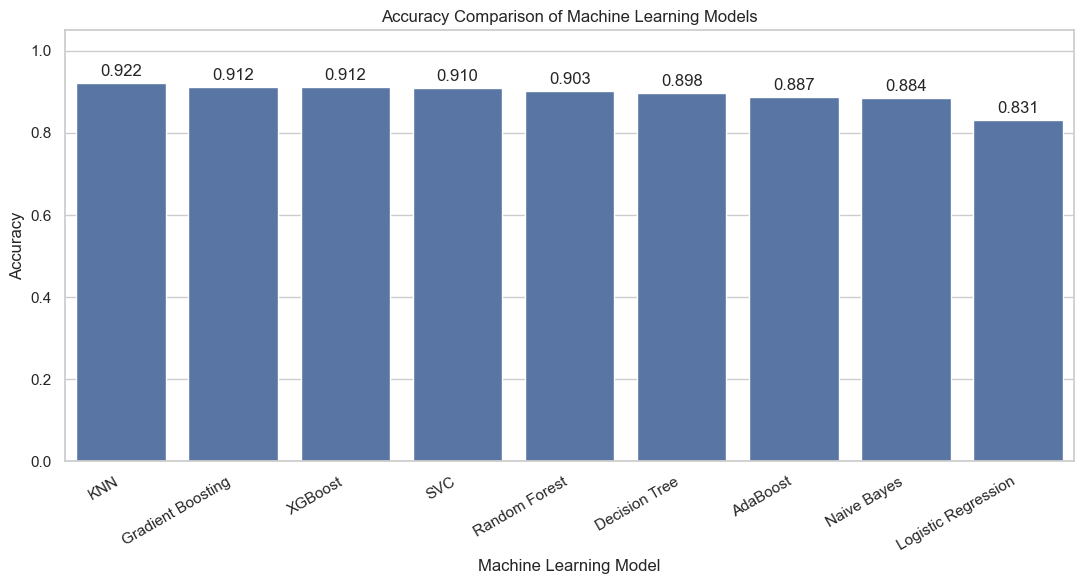

In [ ]:
accuracy_df = pd.DataFrame(model_results).sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)
display(accuracy_df)

plt.figure(figsize=(11, 6))
ax = sns.barplot(data=accuracy_df, x="Model", y="Accuracy")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 20. Best model

In [ ]:
best_model_row = accuracy_df.iloc[0]
print("Best model:", best_model_row["Model"])
print("Accuracy:", round(best_model_row["Accuracy"], 4))

Best model: KNN
Accuracy: 0.922
